# 🚗 Task 3 · Car Price Prediction with Machine Learning

**Oasis Infobyte Internship (OIBSIP) · Data Science Track**
**Intern:** Vinay Singh Chaudhary  |  **Batch:** 5 Oct – 15 Nov 2026

---

### 🎯 Objective
Build a **regression model** that predicts the **selling price of a used vehicle** from features such as brand, age,
kilometres driven, fuel type, seller type and transmission.

### 📦 Dataset — *"Vehicle dataset from cardekho"* (Kaggle) → `data/car_data.csv`
| Column | Meaning |
|--------|---------|
| `Car_Name` | model name (e.g. *city*, *fortuner*, *Royal Enfield Classic 350*) |
| `Year` | year of purchase |
| `Selling_Price` | **target** — price the owner is asking (₹ lakh) |
| `Present_Price` | current ex-showroom price of a new one (₹ lakh) |
| `Kms_Driven` | distance driven (km) |
| `Fuel_Type` | Petrol / Diesel / CNG |
| `Seller_Type` | Dealer / Individual |
| `Transmission` | Manual / Automatic |
| `Owner` | number of previous owners |

### 🗺️ Workflow
Load → Clean (nulls, duplicates, inconsistent text) → Feature engineering (car age, brand, vehicle type) → EDA →
Encoding → Correlation heatmap → Split → Train 4 baseline regressors → Improve with a retained-value target → MAE / RMSE / R² → Feature importance → Predict

## 1️⃣ Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)
print("✅ Setup complete")

✅ Setup complete


## 2️⃣ Load & inspect the data

In [2]:
raw = pd.read_csv("data/car_data.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
raw.info()
print("\nNull values:\n", raw.isnull().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Null values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2


## 3️⃣ Data cleaning
1. **Nulls** — checked above (none in this file, but we keep a safe `dropna` step for robustness).
2. **Duplicates** — exact duplicate rows are removed so the model does not "see" the same car twice.
3. **Inconsistent categorical text** — e.g. `'Petrol'` vs `'petrol'` or stray spaces (`'bajaj  ct 100'`). We strip spaces,
   collapse double spaces and standardise the case of every text column.

In [4]:
df = raw.copy()

# 1) Missing values: drop rows missing the target, fill others (defensive — none exist here)
df = df.dropna(subset=["Selling_Price"])

# 2) Remove exact duplicate rows
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows → {len(df)} rows remain")

# 3) Standardise text columns: trim, collapse repeated spaces, consistent case
df["Car_Name"] = df["Car_Name"].str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    df[col] = df[col].str.strip().str.title()        # 'petrol ' → 'Petrol'

for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(f"{col:13s}:", df[col].value_counts().to_dict())

Removed 2 duplicate rows → 299 rows remain
Fuel_Type    : {'Petrol': 239, 'Diesel': 58, 'Cng': 2}
Seller_Type  : {'Dealer': 193, 'Individual': 106}
Transmission : {'Manual': 260, 'Automatic': 39}


## 4️⃣ Feature engineering
* **Car_Age** = reference year − purchase year. The data was scraped in 2019 (latest model year = 2018),
  so we use `max(Year) + 1` as the reference year — this keeps ages realistic for the time the prices were collected.
* **Brand** — the dataset stores many cars by model only (`'city'`, `'fortuner'`), so the first word is not always the brand.
  We use the first word for two-wheelers (`'bajaj pulsar 150'` → *Bajaj*) and a **model → brand dictionary** for cars.
* **Vehicle_Type** — the file mixes **cars and two-wheelers**; this flag helps the model (bikes are far cheaper).
* **Depreciation_%** is *not* used as a feature because it is computed from the target (that would be data leakage).

In [5]:
# --- 4.1 Car age -------------------------------------------------------------
REFERENCE_YEAR = df["Year"].max() + 1
df["Car_Age"] = REFERENCE_YEAR - df["Year"]

# --- 4.2 Brand extraction ------------------------------------------------------
# Car models that appear without their manufacturer's name
CAR_MODEL_TO_BRAND = {
    "800": "Maruti", "alto": "Maruti", "baleno": "Maruti", "ciaz": "Maruti", "dzire": "Maruti",
    "ertiga": "Maruti", "ignis": "Maruti", "omni": "Maruti", "ritz": "Maruti", "s": "Maruti",
    "swift": "Maruti", "sx4": "Maruti", "vitara": "Maruti", "wagon": "Maruti",
    "camry": "Toyota", "corolla": "Toyota", "etios": "Toyota", "fortuner": "Toyota",
    "innova": "Toyota", "land": "Toyota",
    "amaze": "Honda", "brio": "Honda", "city": "Honda", "jazz": "Honda",
    "creta": "Hyundai", "elantra": "Hyundai", "eon": "Hyundai", "grand": "Hyundai",
    "i10": "Hyundai", "i20": "Hyundai", "verna": "Hyundai", "xcent": "Hyundai",
}
# Two-wheeler brands that DO appear as the first word(s) of the name
TWO_WHEELER_BRANDS = {"bajaj", "hero", "honda", "hyosung", "ktm", "mahindra", "royal",
                      "suzuki", "tvs", "um", "yamaha", "activa"}


def extract_brand(name: str) -> str:
    """Return a clean manufacturer name for a vehicle name string."""
    first = name.split()[0]
    if first in CAR_MODEL_TO_BRAND:                  # model-only car names
        return CAR_MODEL_TO_BRAND[first]
    if first == "royal":
        return "Royal Enfield"
    if first == "activa":                            # 'activa 3g' is a Honda scooter
        return "Honda"
    if first == "um":
        return "UM"
    if first == "ktm" or first == "tvs":
        return first.upper()
    return first.title()                             # 'bajaj' → 'Bajaj'


def vehicle_type(name: str) -> str:
    """Cars are listed in the model→brand dict; everything else is a two-wheeler."""
    return "Car" if name.split()[0] in CAR_MODEL_TO_BRAND else "Two-Wheeler"


df["Brand"] = df["Car_Name"].apply(extract_brand)
df["Vehicle_Type"] = df["Car_Name"].apply(vehicle_type)

print("Reference year:", REFERENCE_YEAR)
print(df["Vehicle_Type"].value_counts().to_dict())
df["Brand"].value_counts()

Reference year: 2019
{'Car': 198, 'Two-Wheeler': 101}


Brand
Honda            70
Hyundai          50
Maruti           49
Toyota           49
Bajaj            25
Royal Enfield    17
Hero             15
Yamaha            8
TVS               8
KTM               4
UM                1
Hyosung           1
Mahindra          1
Suzuki            1
Name: count, dtype: int64

In [6]:
df[["Car_Name", "Year", "Car_Age", "Brand", "Vehicle_Type", "Selling_Price"]].sample(8, random_state=1)

,Car_Name,Year,Car_Age,Brand,Vehicle_Type,Selling_Price
173,hero honda cbz extreme,2011,8,Hero,Two-Wheeler,0.38
287,city,2016,3,Honda,Car,10.11
51,innova,2017,2,Toyota,Car,18.00
146,bajaj pulsar 220 f,2010,9,Bajaj,Two-Wheeler,0.52
214,eon,2016,3,Hyundai,Car,2.90
197,honda cb shine,2007,12,Honda,Two-Wheeler,0.12
274,city,2015,4,Honda,Car,8.65
62,fortuner,2015,4,Toyota,Car,23.50


## 5️⃣ Exploratory Data Analysis
### 5.1 Distribution of selling prices

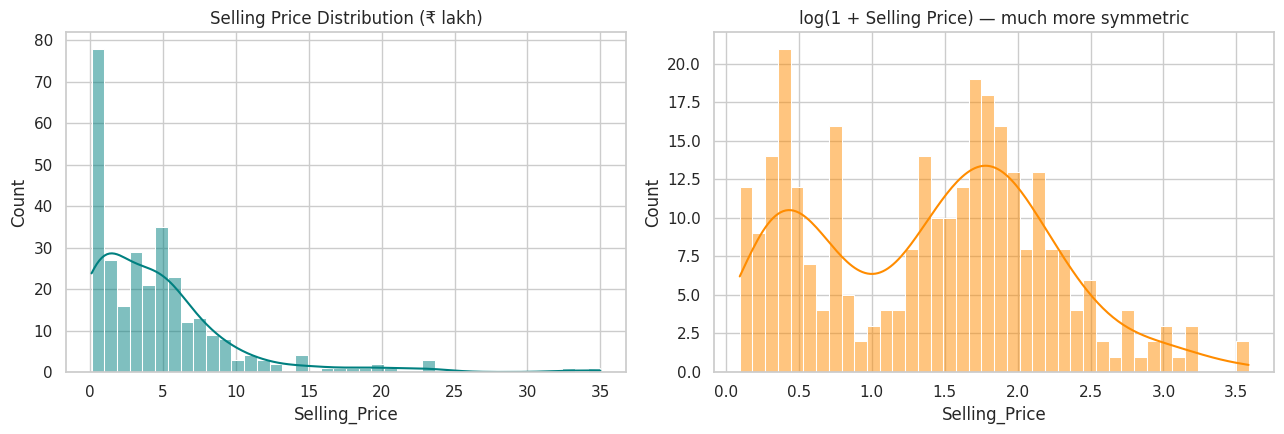

Skewness raw: 2.54 | after log: 0.11


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["Selling_Price"], bins=40, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Selling Price Distribution (₹ lakh)")
sns.histplot(np.log1p(df["Selling_Price"]), bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + Selling Price) — much more symmetric")
plt.tight_layout()
plt.savefig("outputs/01_price_distribution.png", dpi=120, bbox_inches="tight")
plt.show()
print("Skewness raw:", round(df['Selling_Price'].skew(), 2), "| after log:", round(np.log1p(df['Selling_Price']).skew(), 2))

> **Observation:** Prices are strongly **right-skewed** (most vehicles < ₹ 10 lakh, a few luxury SUVs up to ₹ 35 lakh)
> and bimodal — a cluster of cheap two-wheelers near ₹ 0.5 lakh and cars around ₹ 3–8 lakh.

### 5.2 Price vs fuel type, transmission and seller type

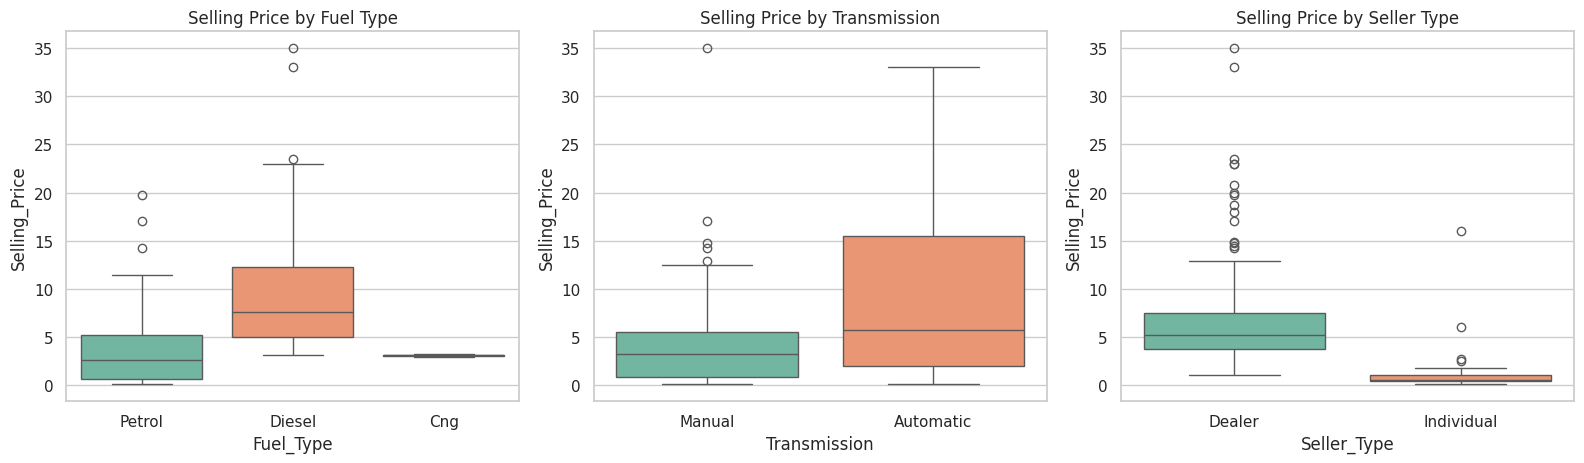

,count,mean,median
Fuel_Type,,,
Cng,2,3.10,3.10
Diesel,58,10.10,7.60
Petrol,239,3.26,2.65


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["Fuel_Type", "Transmission", "Seller_Type"]):
    sns.boxplot(data=df, x=col, y="Selling_Price", hue=col, ax=ax, legend=False)
    ax.set_title(f"Selling Price by {col.replace('_', ' ')}")
plt.tight_layout()
plt.savefig("outputs/02_price_vs_categories.png", dpi=120, bbox_inches="tight")
plt.show()
df.groupby("Fuel_Type")["Selling_Price"].agg(["count", "mean", "median"]).round(2)

> **Observation:** **Diesel** vehicles sell for roughly **3× more** than petrol ones (diesel cars are mostly larger SUVs/sedans),
> **automatics** are pricier than manuals, and **dealers** list higher prices than individuals — partly because
> individuals sell most of the cheap two-wheelers.

### 5.3 Price vs car age & present price

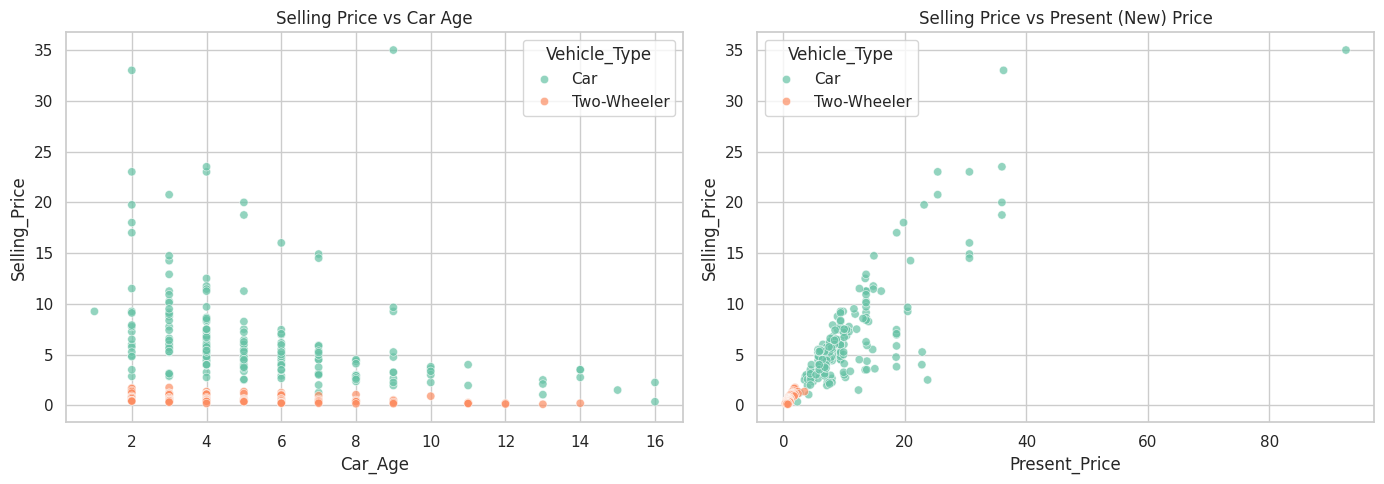

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Vehicle_Type", alpha=0.7, ax=axes[0])
axes[0].set_title("Selling Price vs Car Age")
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Vehicle_Type", alpha=0.7, ax=axes[1])
axes[1].set_title("Selling Price vs Present (New) Price")
plt.tight_layout()
plt.savefig("outputs/03_price_vs_age_and_present_price.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** Price **falls with age** (depreciation), and rises almost linearly with `Present_Price` —
> the price of a new equivalent vehicle is the single strongest signal of resale value.

### 5.4 Average price by brand

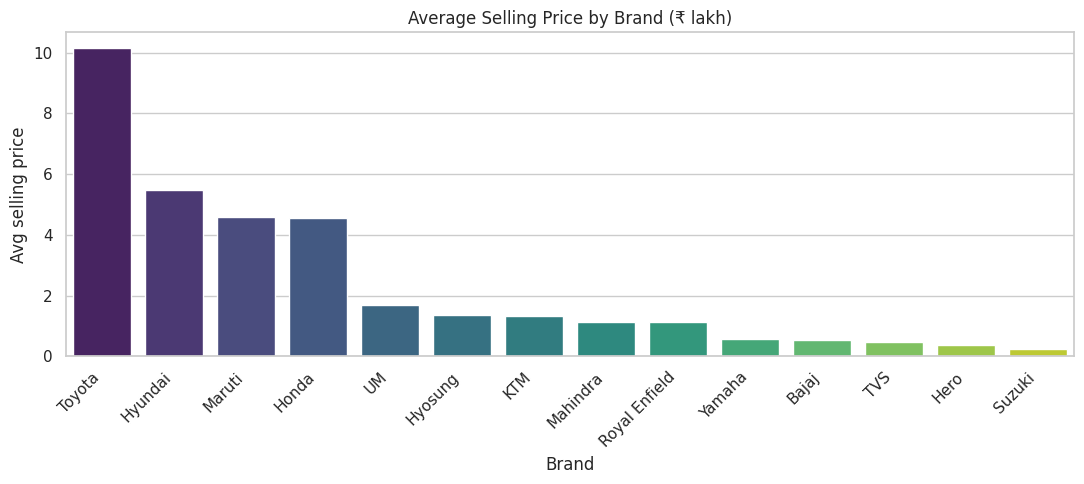

In [10]:
brand_price = df.groupby("Brand")["Selling_Price"].mean().sort_values(ascending=False)
plt.figure(figsize=(11, 5))
sns.barplot(x=brand_price.index, y=brand_price.values, hue=brand_price.index, palette="viridis", legend=False)
plt.xticks(rotation=45, ha="right")
plt.title("Average Selling Price by Brand (₹ lakh)")
plt.ylabel("Avg selling price")
plt.tight_layout()
plt.savefig("outputs/04_brand_avg_price.png", dpi=120, bbox_inches="tight")
plt.show()

## 6️⃣ Encode categorical variables
* **One-Hot Encoding** (`pd.get_dummies`, `drop_first=True`) for `Fuel_Type`, `Seller_Type`, `Transmission`, `Vehicle_Type`, `Brand`.
  One-hot avoids implying a false order (Label Encoding would tell a linear model that *Diesel > Petrol*).
* `Car_Name` and `Year` are dropped — `Brand` / `Car_Age` carry their information in a cleaner form.

In [11]:
model_df = df.drop(columns=["Car_Name", "Year"])
model_df = pd.get_dummies(model_df, columns=["Fuel_Type", "Seller_Type", "Transmission", "Vehicle_Type", "Brand"],
                          drop_first=True, dtype=int)
print("Encoded shape:", model_df.shape)
model_df.head()

Encoded shape: (299, 23)


,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,Vehicle_Type_Two-Wheeler,...,Brand_Hyundai,Brand_KTM,Brand_Mahindra,Brand_Maruti,Brand_Royal Enfield,Brand_Suzuki,Brand_TVS,Brand_Toyota,Brand_UM,Brand_Yamaha
0,3.35,5.59,27000,0,5,0,1,0,1,0,...,0,0,0,1,0,0,0,0,0,0
1,4.75,9.54,43000,0,6,1,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,7.25,9.85,6900,0,2,0,1,0,1,0,...,0,0,0,1,0,0,0,0,0,0
3,2.85,4.15,5200,0,8,0,1,0,1,0,...,0,0,0,1,0,0,0,0,0,0
4,4.60,6.87,42450,0,5,1,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0


## 7️⃣ Feature correlation heatmap

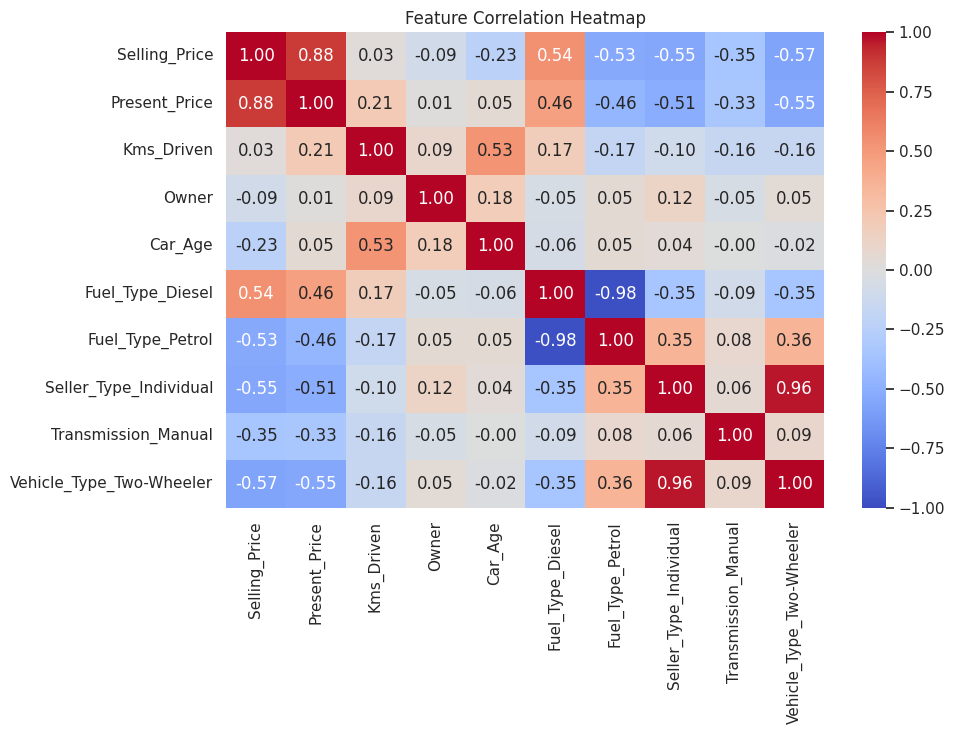

Present_Price               0.876
Fuel_Type_Diesel            0.544
Kms_Driven                  0.029
Owner                      -0.088
Car_Age                    -0.234
Transmission_Manual        -0.349
Fuel_Type_Petrol           -0.532
Seller_Type_Individual     -0.554
Vehicle_Type_Two-Wheeler   -0.567
Name: Selling_Price, dtype: float64

In [12]:
core_cols = ["Selling_Price", "Present_Price", "Kms_Driven", "Owner", "Car_Age",
             "Fuel_Type_Diesel", "Fuel_Type_Petrol", "Seller_Type_Individual",
             "Transmission_Manual", "Vehicle_Type_Two-Wheeler"]
plt.figure(figsize=(10, 7.5))
sns.heatmap(model_df[core_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/05_correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()
model_df[core_cols].corr()["Selling_Price"].drop("Selling_Price").sort_values(ascending=False).round(3)

> **Observation:** `Present_Price` (**+0.88**) and `Fuel_Type_Diesel` (+0.55) push price up;
> being sold by an individual, being a two-wheeler, manual transmission and higher age push it down.

## 8️⃣ Train / test split

In [13]:
X = model_df.drop(columns="Selling_Price")
y = model_df["Selling_Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (239, 22) | Test: (60, 22)


## 9️⃣ Train & evaluate regression models
Metrics:
* **MAE** – average absolute error in ₹ lakh (easy to explain: "we are off by X lakh on average").
* **RMSE** – like MAE but punishes big errors more.
* **R²** – share of price variance explained (1.0 = perfect).

We also report **5-fold cross-validated R²** because the dataset is small (299 rows) and a single split can be lucky or unlucky.

### 9.1 Round 1 — predict the raw selling price

In [14]:
def evaluate(name, model):
    """Fit on the training set, score on the test set and with 5-fold CV. Returns (metrics dict, predictions)."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 (test)": r2_score(y_test, pred),
        "R2 (5-fold CV)": cross_val_score(model, X, y, cv=kf, scoring="r2").mean(),
    }, pred


kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=3, random_state=RANDOM_STATE),
}
rows, predictions, fitted = [], {}, {}
for name, model in base_models.items():
    metrics, predictions[name] = evaluate(name, model)
    rows.append(metrics)
    fitted[name] = model
pd.DataFrame(rows).round(3)

,Model,MAE,RMSE,R2 (test),R2 (5-fold CV)
0,Linear Regression,1.582,2.715,0.714,0.834
1,Decision Tree,1.091,2.058,0.836,0.921
2,Random Forest,1.427,3.465,0.534,0.854
3,Gradient Boosting,1.207,2.803,0.695,0.888


> **Problem spotted:** test R² is unstable (0.53–0.84) even though CV R² is ≈ 0.83–0.92.
> The test set contains a **₹ 33 lakh Fortuner** — tree models cannot predict above the prices they have seen often,
> and one big miss dominates RMSE. We need a target that behaves the same for a ₹ 0.5 lakh bike and a ₹ 30 lakh SUV.

### 9.2 Round 2 — model the *retained-value ratio* (domain-driven improvement)
Instead of predicting the price directly, we predict **what fraction of its new price a vehicle keeps**:

$$\text{ratio} = \frac{\text{Selling\_Price}}{\text{Present\_Price}} \qquad \Rightarrow \qquad \widehat{\text{price}} = \widehat{\text{ratio}} \times \text{Present\_Price}$$

This is how dealers actually think ("a 5-year-old diesel keeps ~60 % of its value"). The ratio lies in a narrow 0–1 range
for every vehicle, so the model learns **depreciation patterns** (age, km, fuel, owner…) that transfer across price levels.
There is **no leakage**: `Present_Price` is a normal input feature available at prediction time.

In [15]:
from sklearn.base import BaseEstimator, RegressorMixin, clone


class RetainedValueRegressor(BaseEstimator, RegressorMixin):
    """Wraps any regressor: trains it on Selling_Price / Present_Price, predicts ratio × Present_Price."""

    def __init__(self, regressor=None):
        self.regressor = regressor

    def fit(self, X, y):
        self.regressor_ = clone(self.regressor).fit(X, y / X["Present_Price"])
        return self

    def predict(self, X):
        return self.regressor_.predict(X) * X["Present_Price"].to_numpy()


ratio_models = {
    "Linear Regression (ratio)": RetainedValueRegressor(LinearRegression()),
    "Random Forest (ratio)": RetainedValueRegressor(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)),
    "Gradient Boosting (ratio)": RetainedValueRegressor(GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
}
for name, model in ratio_models.items():
    metrics, predictions[name] = evaluate(name, model)
    rows.append(metrics)
    fitted[name] = model

results = pd.DataFrame(rows).sort_values("R2 (5-fold CV)", ascending=False).reset_index(drop=True)
results.round(3)

,Model,MAE,RMSE,R2 (test),R2 (5-fold CV)
0,Gradient Boosting (ratio),0.576,0.889,0.969,0.975
1,Random Forest (ratio),0.631,1.010,0.960,0.973
2,Decision Tree,1.091,2.058,0.836,0.921
3,Gradient Boosting,1.207,2.803,0.695,0.888
4,Random Forest,1.427,3.465,0.534,0.854
5,Linear Regression,1.582,2.715,0.714,0.834
6,Linear Regression (ratio),0.717,1.260,0.938,0.760


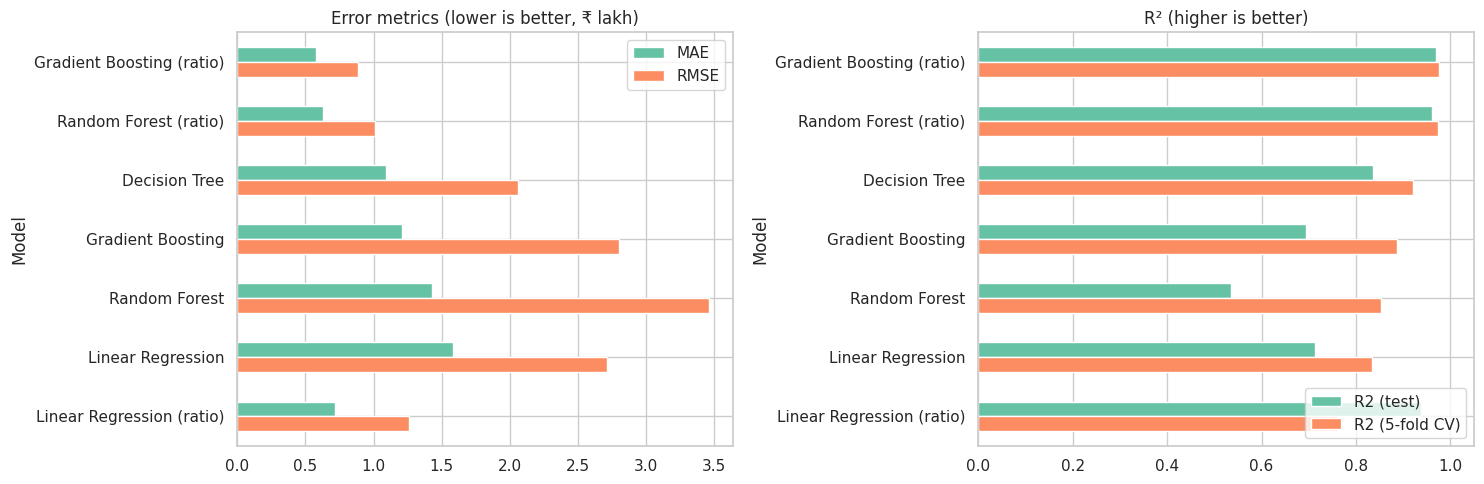

In [16]:
# Visual comparison of every model
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
results.set_index("Model")[["MAE", "RMSE"]].plot(kind="barh", ax=axes[0])
axes[0].set_title("Error metrics (lower is better, ₹ lakh)")
results.set_index("Model")[["R2 (test)", "R2 (5-fold CV)"]].plot(kind="barh", ax=axes[1])
axes[1].set_xlim(0, 1.05)
axes[1].set_title("R² (higher is better)")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/06_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 🔟 Best model — actual vs predicted & feature importance

🏆 Best model: Gradient Boosting (ratio)
Model             Gradient Boosting (ratio)
MAE                                0.576126
RMSE                               0.888786
R2 (test)                           0.96935
R2 (5-fold CV)                     0.975459


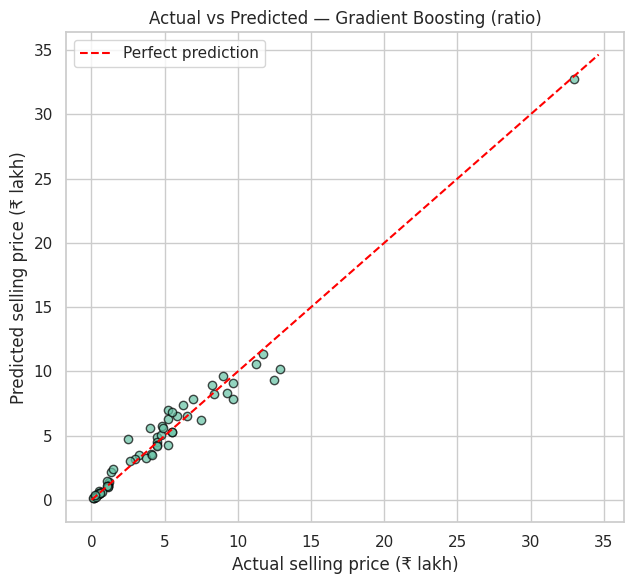

In [17]:
best_name = results.loc[0, "Model"]
best_model = fitted[best_name]
print(f"🏆 Best model: {best_name}")
print(results.loc[0].to_string())

plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, predictions[best_name], alpha=0.7, edgecolor="k")
lims = [0, max(y_test.max(), predictions[best_name].max()) * 1.05]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual selling price (₹ lakh)")
plt.ylabel("Predicted selling price (₹ lakh)")
plt.title(f"Actual vs Predicted — {best_name}")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/07_actual_vs_predicted.png", dpi=120, bbox_inches="tight")
plt.show()

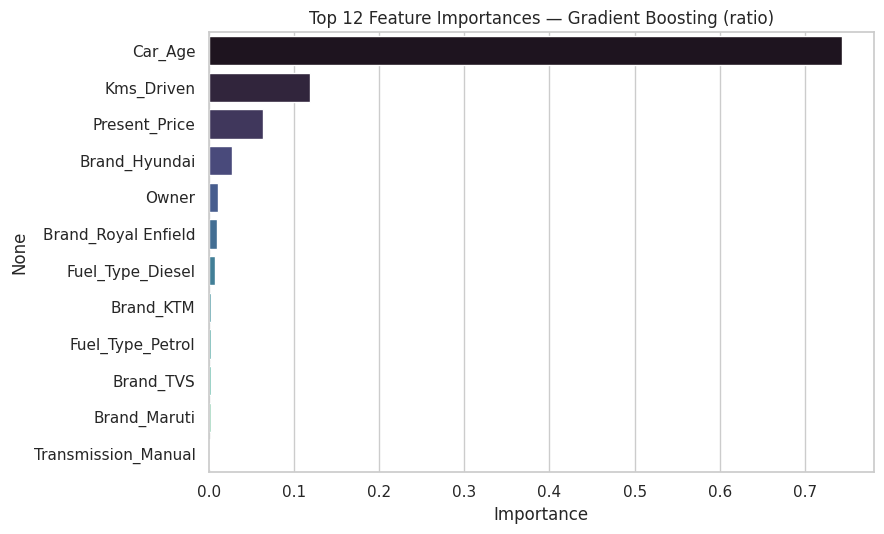

Car_Age                0.744
Kms_Driven             0.119
Present_Price          0.064
Brand_Hyundai          0.027
Owner                  0.011
Brand_Royal Enfield    0.010
Fuel_Type_Diesel       0.008
Brand_KTM              0.003
Fuel_Type_Petrol       0.003
Brand_TVS              0.003
Brand_Maruti           0.002
Transmission_Manual    0.002
dtype: float64

In [18]:
# Feature importance of the tree ensemble inside the wrapper (importance for predicting the retained-value ratio)
inner = best_model.regressor_ if hasattr(best_model, "regressor_") else best_model
importances = pd.Series(inner.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="mako", legend=False)
plt.title(f"Top 12 Feature Importances — {best_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("outputs/08_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
importances.round(3)

> **Interpretation:** Once the new price is factored in, **Car_Age (≈ 74 %)** is by far the dominant driver of how much value a vehicle keeps,
> followed by **Kms_Driven (≈ 12 %)** and **Present_Price (≈ 6 %)** (expensive cars depreciate differently from cheap bikes).
> Brand (e.g. Hyundai, Royal Enfield), number of owners and fuel type add smaller corrections.

## 1️⃣1️⃣ Predict the price of a new listing

In [19]:
def predict_price(present_price, kms_driven, owner, year, fuel, seller, transmission, brand, vehicle="Car"):
    """Build a one-row input with the same encoded columns as training data and predict the price."""
    row = pd.DataFrame(0, index=[0], columns=X.columns)
    row["Present_Price"], row["Kms_Driven"], row["Owner"] = present_price, kms_driven, owner
    row["Car_Age"] = REFERENCE_YEAR - year
    for col in [f"Fuel_Type_{fuel}", f"Seller_Type_{seller}", f"Transmission_{transmission}",
                f"Vehicle_Type_{vehicle}", f"Brand_{brand}"]:
        if col in row.columns:          # the dropped (baseline) category simply stays 0
            row[col] = 1
    return best_model.predict(row)[0]


example = predict_price(present_price=9.5, kms_driven=35000, owner=0, year=2015,
                        fuel="Diesel", seller="Dealer", transmission="Manual", brand="Honda")
print(f"Predicted selling price for a 2015 diesel Honda (new price ₹9.5 lakh): ₹ {example:.2f} lakh")

Predicted selling price for a 2015 diesel Honda (new price ₹9.5 lakh): ₹ 6.24 lakh


## ✅ Conclusions
- Cleaned the data (2 duplicates removed, text standardised) and engineered **Car_Age**, **Brand** and **Vehicle_Type**.
- **Present (new) price** sets the price level; **age and kilometres driven** decide how much of it is retained. Diesel and automatic vehicles sell for more.
- Seven model variants were compared on MAE, RMSE and R². Predicting the raw price was unstable (test R² 0.5–0.8) because
  of rare expensive SUVs.
- **Key improvement:** modelling the *retained-value ratio* (selling ÷ new price) lifted the best model to **R² ≈ 0.97**
  and cut MAE roughly in half (≈ ₹ 0.6 lakh) — a domain-driven idea that beats simply trying bigger models.

**Future scope:** larger dataset (CarDekho v3 with engine/power/mileage), hyper-parameter tuning, log-target modelling, deploy as a web app.

---
*Submitted by **Vinay Singh Chaudhary** for the Oasis Infobyte Data Science Internship · #oasisinfobyte*